**Practical No. 1**

---


Vacuum Cleaner Agent using Artificial Intelligence (Simple Reflex agent)

**Name:** Tejas Narayan Mahamuni

**PRN:** 202401040036

**Roll No.** 7

**Github Link:** https://github.com/tejas-mahamuni/machine-learning.git



**Aim**

To design and implement a Simple Reflex Agent for an autonomous vacuum cleaner using python

**Objective**

1. To understand the working of a Simple Reflex Agent.
2. To represent a vacuum cleaner's environment using programmatic states.
3. To implement condition-action rules for cleaning and movement.
4. To simulate dynamic environmental changes and maintenance operations.
5. To observe the agent's behaviour through the simulation output.

**PEAS**

* **Performance (P):** Maximize cleaned rooms (+1 score), keep all 4 rooms clean, avoid running out of water or battery.
* **Environment (E):** 4 Rooms (A, B, C, D), charging/refill dock in Room A, recurring random dirt.
* **Actuators (A):** Wheels (movement), vacuum suction/mop, docking connector, water intake valve.
* **Sensors (S):** Room location detector, dirt sensor (0/1), water level gauge (0–100%), elapsed time clock.

**Agent - Environment Flow**

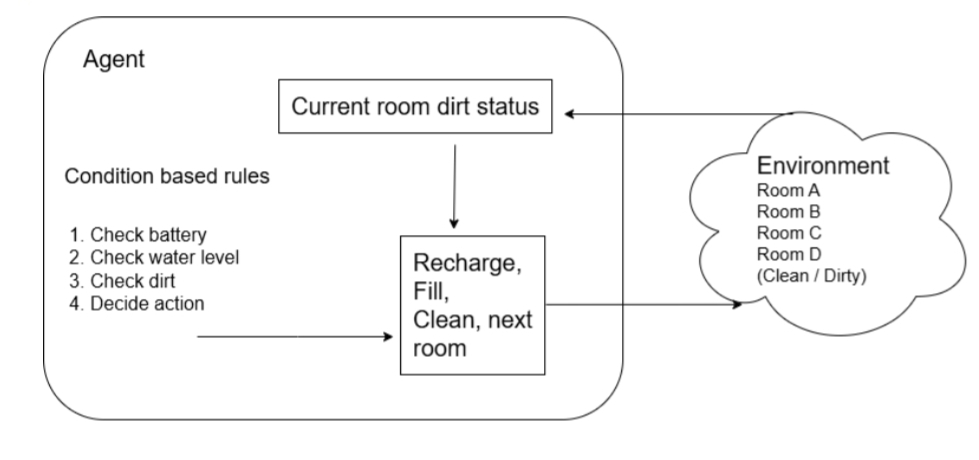

**Flowchart**

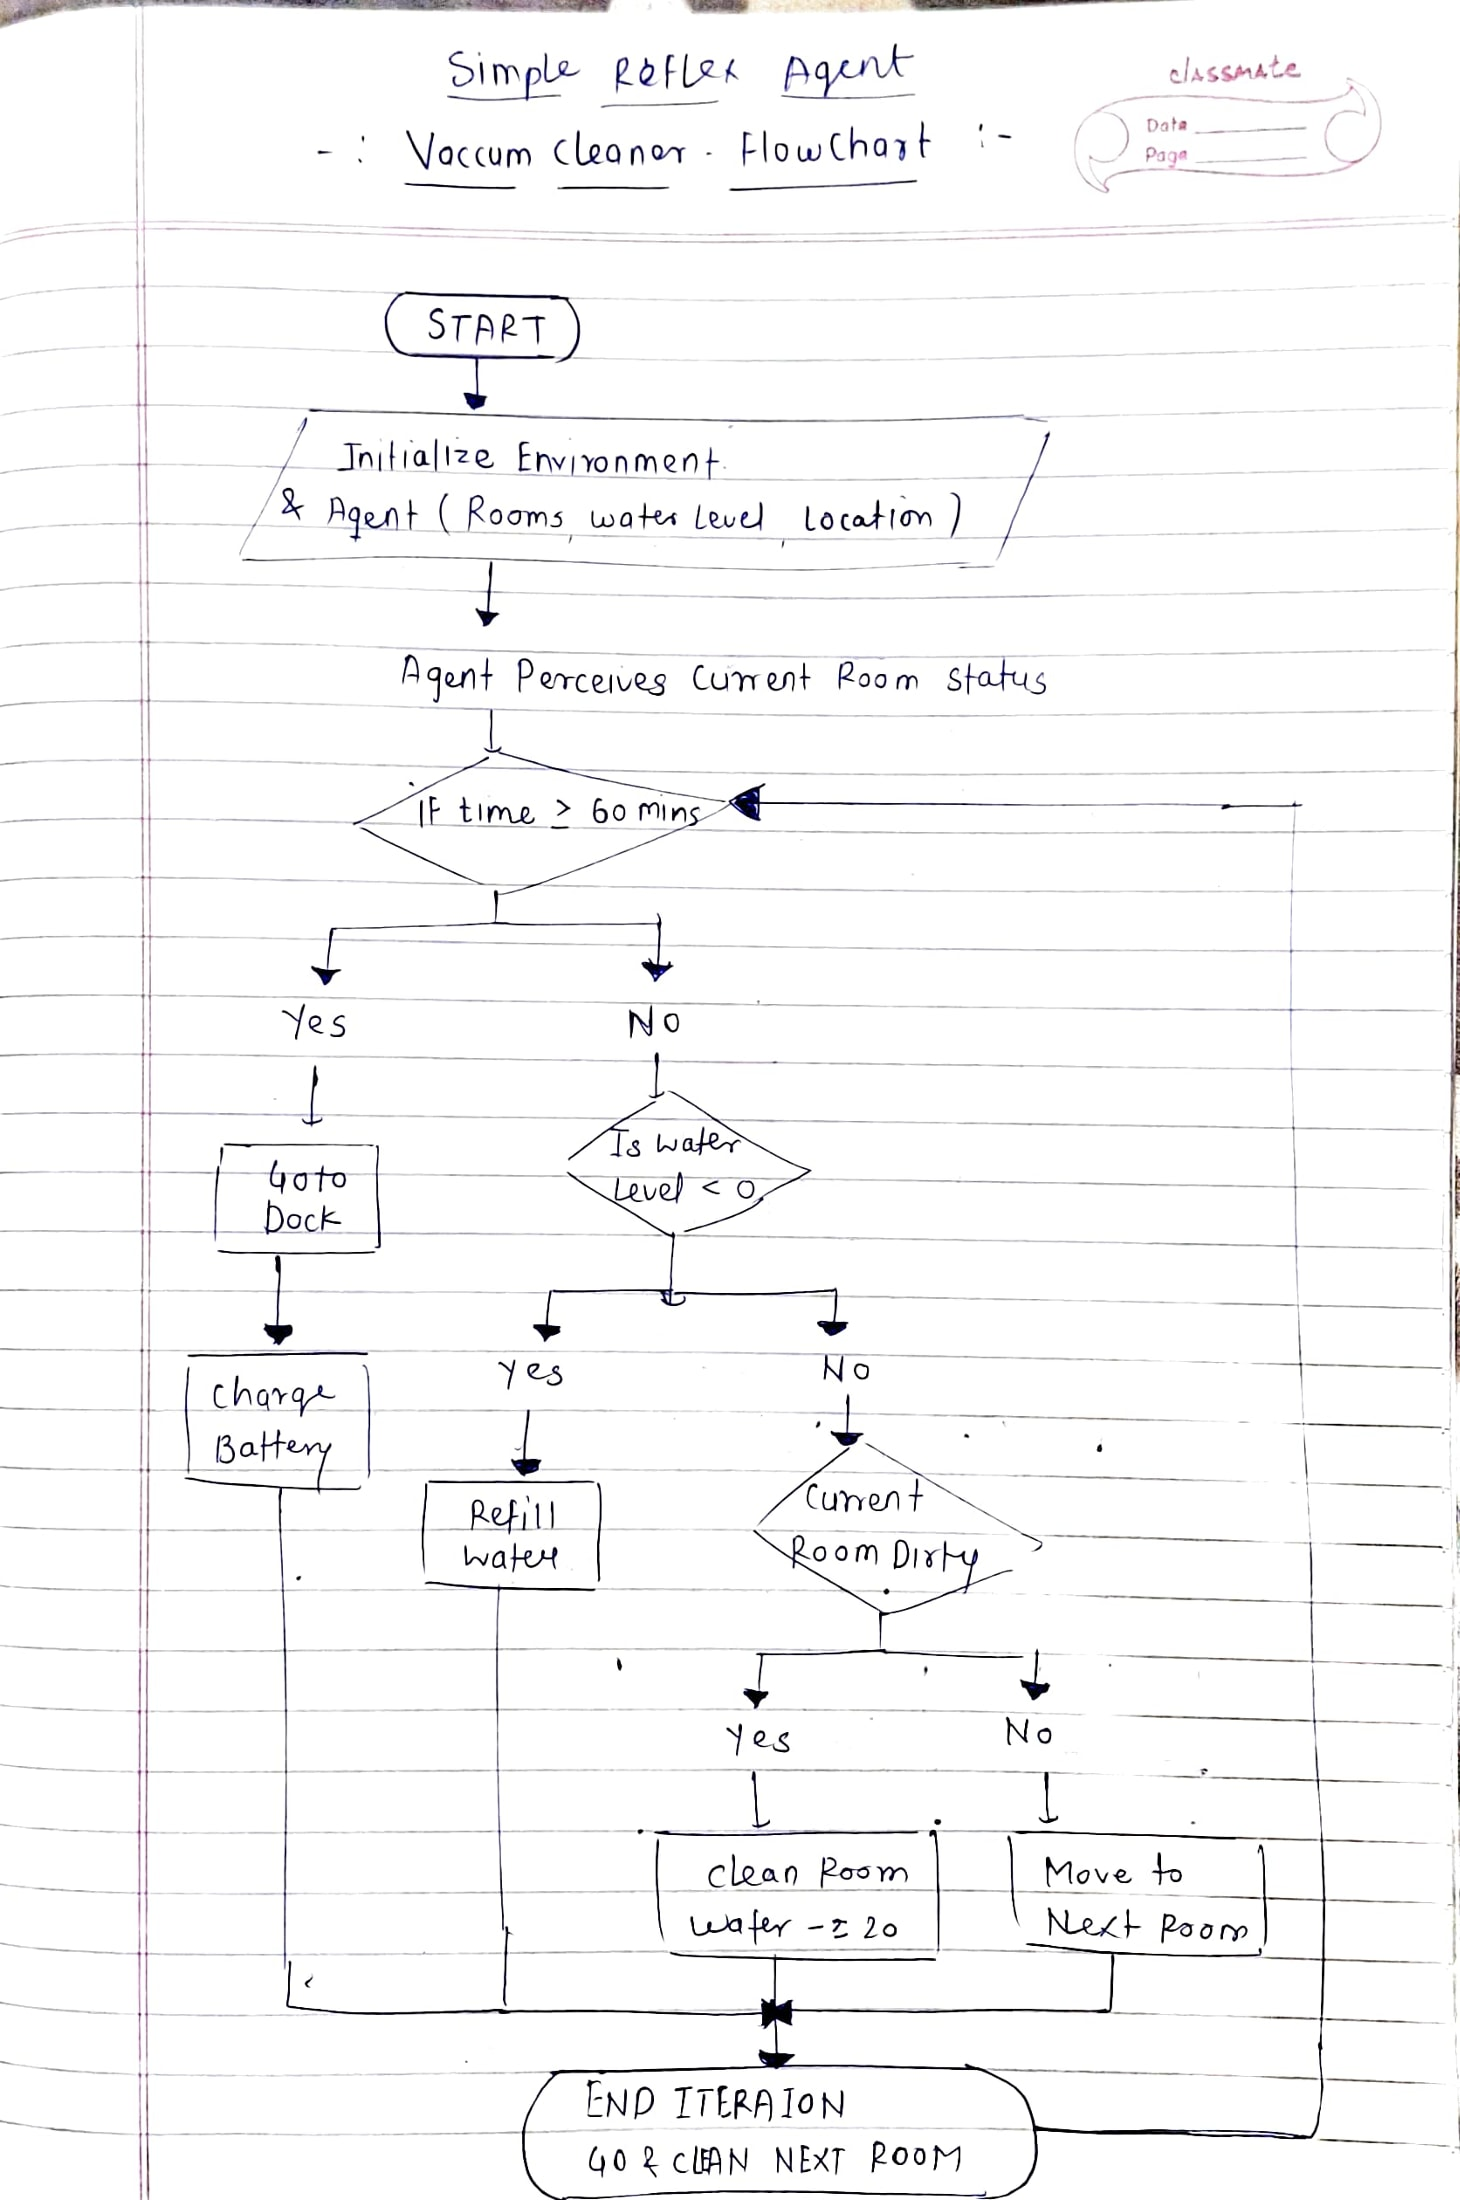

In [4]:
import random
import time

class Environment:
    def __init__(self):
        # 1 = Dirty, 0 = Clean
        self.rooms = {
            'A': random.randint(0, 1),
            'B': random.randint(0, 1),
            'C': random.randint(0, 1),
            'D': random.randint(0, 1)
        }

    def all_cleaned(self):
        """Returns True if every room status is 0 (Clean)."""
        return all(status == 0 for status in self.rooms.values())


class VacuumAgent:
    def __init__(self):
        self.room_keys = ['A', 'B', 'C', 'D']
        self.vaccumLocation = 0  # Starts in Room A (Dock)
        self.waterLevel = 100
        self.startTime = time.time()
        self.score = 0

    def step(self, environment):
        
        total_time = time.time() - self.startTime
        current_room = self.room_keys[self.vaccumLocation]

        print(f"Status: Location = Room {current_room} | Water = {self.waterLevel}% | Elapsed Time = {total_time:.1f}s")

        # Rule 1: Recharge Maintenance (Time Limit Check)
        if total_time >= 30:

            print(f"\n[MAINTENANCE] Operating time limit reached! Returning to Dock (Room A)...")
            self.vaccumLocation = 0  # Move to Room A

            print("Charging for 5 seconds...")
            time.sleep(5)

            self.startTime = time.time()  # Reset timer
            print("Fully charged! Resuming tasks.\n")

        # Rule 2: Water Refill Maintenance (50% reduction means refill every 2 cleaned rooms)
        elif self.waterLevel <= 0:

            print(f"\n[MAINTENANCE] Water tank empty (0%)! Returning to Dock (Room A)...")
            self.vaccumLocation = 0  # Move to Room A

            print("Refilling water tank...")
            time.sleep(1)

            self.waterLevel = 100
            print("Water refilled to 100%!\n")

        # Rule 3: Current Room is Dirty -> Clean Action
        elif environment.rooms[current_room] == 1:

            print(f"\nRoom {current_room} is DIRTY. Cleaning room...")
            environment.rooms[current_room] = 0

            self.waterLevel -= 50  # Reduces 50% per clean
            self.score += 1

            print(f"Room {current_room} is now CLEAN! (Remaining Water: {self.waterLevel}%)\n")

        # Rule 4: Current Room is Clean -> Move to Next Room
        else:
            print(f"\nRoom {current_room} is ALREADY CLEAN.")

            prev_room = current_room
            self.vaccumLocation = (self.vaccumLocation + 1) % 4
            next_room = self.room_keys[self.vaccumLocation]
            self.score -= 1

            print(f"Moving from Room {prev_room} to Room {next_room}...\n")


def run():
    env = Environment()
    agent = VacuumAgent()

    print("--- SIMULATION STARTED ---")
    print(f"Initial Room States: {env.rooms}\n")

    step_counter = 1

    # Loop executes only until all 4 rooms are confirmed clean
    while not env.all_cleaned():
        print(f"--- STEP {step_counter} ---")
        agent.step(env)
        print(f"Current Rooms State: {env.rooms}")
        print(f"Current Score: {agent.score}\n")
        
        step_counter += 1
        time.sleep(1)

    # Final Docking Step after clearing all rooms
    print("=" * 45)

    print("ALL ROOMS ARE CLEANED!")

    if agent.vaccumLocation != 0:
        print("Agent navigating back to Room A (Dock) for final docking...")
        agent.vaccumLocation = 0

    print(f"Agent successfully parked at Charging Dock (Room A).")
    print(f"Final Performance Score: {agent.score}")
    print(f"Final Room States: {env.rooms}")

    print("=" * 45)


if __name__ == "__main__":
    run()

--- SIMULATION STARTED ---
Initial Room States: {'A': 1, 'B': 1, 'C': 1, 'D': 0}

--- STEP 1 ---
Status: Location = Room A | Water = 100% | Elapsed Time = 0.0s

Room A is DIRTY. Cleaning room...
Room A is now CLEAN! (Remaining Water: 50%)

Current Rooms State: {'A': 0, 'B': 1, 'C': 1, 'D': 0}
Current Score: 1

--- STEP 2 ---
Status: Location = Room A | Water = 50% | Elapsed Time = 1.0s

Room A is ALREADY CLEAN.
Moving from Room A to Room B...

Current Rooms State: {'A': 0, 'B': 1, 'C': 1, 'D': 0}
Current Score: 0

--- STEP 3 ---
Status: Location = Room B | Water = 50% | Elapsed Time = 2.1s

Room B is DIRTY. Cleaning room...
Room B is now CLEAN! (Remaining Water: 0%)

Current Rooms State: {'A': 0, 'B': 0, 'C': 1, 'D': 0}
Current Score: 1

--- STEP 4 ---
Status: Location = Room B | Water = 0% | Elapsed Time = 3.1s

[MAINTENANCE] Water tank empty (0%)! Returning to Dock (Room A)...
Refilling water tank...
Water refilled to 100%!

Current Rooms State: {'A': 0, 'B': 0, 'C': 1, 'D': 0}
Curre

**Conclusion**

The vacuum cleaner simulation successfully demonstrates the basic working principle of Simple Reflex Agent. The agent oberves the current environment and selects an appropriate action using predefined condition-action rules. The simulation also demonstrates that even a simple rule based agent can handle cleaning, movement and basic maintenance tasks in a changing environment.